In [3]:
# import libraries and path
import os
import re
from pathlib import Path

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# Base folder on your machine
BASE = Path(r"C:\Users\Admin\Endometriosis\endometriosis")

# Dataset root inside it
ROOT = BASE / "UT-EndoMRI"

# Where audit outputs go
AUDIT = Path(r"C:\Users\Admin\Endometriosis\endo_project\audit")
AUDIT.mkdir(parents=True, exist_ok=True)

print("BASE exists:", BASE.exists())
print("ROOT exists:", ROOT.exists())
print("Centres:", [p.name for p in ROOT.iterdir() if p.is_dir()])


BASE exists: True
ROOT exists: True
Centres: ['D1_MHS', 'D2_TCPW']


In [4]:
# list the subjects
subjects = []

for centre in ["D1_MHS", "D2_TCPW"]:
    cdir = ROOT / centre
    if not cdir.exists():
        print("Missing centre:", centre)
        continue
    for subj_dir in sorted(cdir.iterdir()):
        if subj_dir.is_dir() and subj_dir.name.startswith(("D1-", "D2-")):
            subjects.append({
                "subject": subj_dir.name,
                "centre": centre,
                "path": str(subj_dir),
            })

df_subj = pd.DataFrame(subjects)
print("Total subjects:", len(df_subj))
print(df_subj.groupby("centre").size())
df_subj.head()

Total subjects: 124
centre
D1_MHS     51
D2_TCPW    73
dtype: int64


,subject,centre,path
0,D1-000,D1_MHS,C:\Users\Admin\Endometriosis\endometriosis\UT-...
1,D1-001,D1_MHS,C:\Users\Admin\Endometriosis\endometriosis\UT-...
2,D1-002,D1_MHS,C:\Users\Admin\Endometriosis\endometriosis\UT-...
3,D1-003,D1_MHS,C:\Users\Admin\Endometriosis\endometriosis\UT-...
4,D1-004,D1_MHS,C:\Users\Admin\Endometriosis\endometriosis\UT-...


In [5]:
# parse evey file in the dataset
FILE_RE = re.compile(
    r"^(D[12]-\d+)_(T1|T2|T1FS|T2FS|em|ov|ut)(?:_r(\d))?\.nii\.gz$"
)

records = []

for _, row in tqdm(df_subj.iterrows(), total=len(df_subj)):
    subj = row["subject"]
    centre = row["centre"]
    sdir = Path(row["path"])

    for f in sdir.iterdir():
        m = FILE_RE.match(f.name)
        if not m:
            continue
        sid, modality, rater = m.group(1), m.group(2), m.group(3)
        try:
            img = nib.load(str(f))
            shape = tuple(int(s) for s in img.shape)
            spacing = tuple(round(float(z), 3) for z in img.header.get_zooms()[:3])
            records.append({
                "subject": sid, "centre": centre,
                "modality": modality, "rater": rater,
                "file": f.name, "shape": shape, "spacing": spacing,
                "path": str(f),
            })
        except Exception as e:
            records.append({
                "subject": sid, "centre": centre,
                "modality": modality, "rater": rater,
                "file": f.name, "error": str(e), "path": str(f),
            })

df_files = pd.DataFrame(records)
print("Total files parsed:", len(df_files))
df_files.head()

  0%|          | 0/124 [00:00<?, ?it/s]

Total files parsed: 685


,subject,centre,modality,rater,file,shape,spacing,path
0,D1-000,D1_MHS,em,1,D1-000_em_r1.nii.gz,"(480, 480, 32)","(0.5, 0.5, 5.0)",C:\Users\Admin\Endometriosis\endometriosis\UT-...
1,D1-000,D1_MHS,em,2,D1-000_em_r2.nii.gz,"(480, 480, 32)","(0.5, 0.5, 5.0)",C:\Users\Admin\Endometriosis\endometriosis\UT-...
2,D1-000,D1_MHS,em,3,D1-000_em_r3.nii.gz,"(480, 480, 32)","(0.5, 0.5, 5.0)",C:\Users\Admin\Endometriosis\endometriosis\UT-...
3,D1-000,D1_MHS,ov,1,D1-000_ov_r1.nii.gz,"(480, 480, 32)","(0.5, 0.5, 5.0)",C:\Users\Admin\Endometriosis\endometriosis\UT-...
4,D1-000,D1_MHS,T1FS,NaN,D1-000_T1FS.nii.gz,"(480, 480, 32)","(0.5, 0.5, 5.0)",C:\Users\Admin\Endometriosis\endometriosis\UT-...


In [6]:
# wat sequences exist in the dataset
print("Modality counts across whole dataset:")
print(df_files["modality"].value_counts())

print("\nSequences only (images):")
seqs = df_files[df_files["modality"].isin(["T1", "T2", "T1FS", "T2FS"])]
print(seqs["modality"].value_counts())

print("\nMasks only:")
masks = df_files[df_files["modality"].isin(["em", "ov", "ut"])]
print(masks["modality"].value_counts())

Modality counts across whole dataset:
modality
ut      144
ov      125
T1FS    104
T2       92
em       81
T2FS     70
T1       69
Name: count, dtype: int64

Sequences only (images):
modality
T1FS    104
T2       92
T2FS     70
T1       69
Name: count, dtype: int64

Masks only:
modality
ut    144
ov    125
em     81
Name: count, dtype: int64


In [7]:
# raters per modality per centre
rater_table = (
    masks.groupby(["centre", "modality", "rater"])
         .size()
         .unstack(fill_value=0)
)
print(rater_table)

rater             1   2   3
centre modality            
D1_MHS em         9  21  40
       ov        10  19  38
       ut         9  26  47


In [8]:
# label values inside masks
def unique_values(path, max_voxels=5_000_000):
    img = nib.load(path)
    data = np.asanyarray(img.dataobj)
    if data.size > max_voxels:
        flat = data.ravel()[:: data.size // max_voxels]
    else:
        flat = data.ravel()
    return sorted(np.unique(flat).astype(int).tolist())

for modality in ["em", "ov", "ut"]:
    sub = masks[masks["modality"] == modality].head(10)
    print(f"\nModality: {modality}")
    for _, r in sub.iterrows():
        try:
            vals = unique_values(r["path"])
            print(f"  {r['subject']} r{r['rater']}: {vals}")
        except Exception as e:
            print(f"  {r['subject']} r{r['rater']}: ERROR {e}")


Modality: em
  D1-000 r1: [0, 1]
  D1-000 r2: [0, 1, 2]
  D1-000 r3: [0, 1]
  D1-001 r1: [0, 1]
  D1-001 r2: [0, 1]
  D1-001 r3: [0, 1]
  D1-003 r1: [0, 1]
  D1-003 r2: [0, 1]
  D1-003 r3: [0, 1]
  D1-004 r3: [0, 1]

Modality: ov
  D1-000 r1: [0, 1]
  D1-001 r1: [0, 1]
  D1-001 r2: [0, 1]
  D1-001 r3: [0, 1]
  D1-002 r1: [0, 1]
  D1-002 r2: [0, 1]
  D1-002 r3: [0, 1]
  D1-003 r1: [0, 1]
  D1-003 r3: [0, 1]
  D1-004 r1: [0, 1, 2]

Modality: ut
  D1-000 r1: [0, 1]
  D1-000 r2: [0, 1]
  D1-000 r3: [0, 1]
  D1-001 r1: [0, 1]
  D1-001 r2: [0, 1]
  D1-001 r3: [0, 1]
  D1-002 r1: [0, 1]
  D1-002 r2: [0, 1]
  D1-002 r3: [0, 1]
  D1-003 r1: [0, 1]


In [9]:
# spacing and shape distribution
shapes = pd.DataFrame(seqs["shape"].tolist(), columns=["x", "y", "z"])
spacings = pd.DataFrame(seqs["spacing"].tolist(), columns=["sx", "sy", "sz"])

print("Shape stats:")
print(shapes.describe().round(1))
print("\nSpacing stats (mm):")
print(spacings.describe().round(3))

Shape stats:
           x      y      z
count  335.0  335.0  335.0
mean   390.0  388.2   66.2
std    152.7  149.4   28.9
min    224.0  224.0   30.0
25%    256.0  256.0   37.0
50%    352.0  352.0   68.0
75%    480.0  480.0   86.5
max    880.0  880.0  170.0

Spacing stats (mm):
            sx       sy       sz
count  335.000  335.000  335.000
mean     0.803    0.803    4.223
std      0.248    0.248    1.807
min      0.414    0.414    1.500
25%      0.500    0.500    2.500
50%      0.781    0.781    4.400
75%      1.042    1.042    6.000
max      1.246    1.246    7.200


In [10]:
# which masks are empty(no lesions/organs present)
def nonzero_count(path, threshold=0):
    img = nib.load(path)
    data = np.asanyarray(img.dataobj)
    return int((data > threshold).sum())

rows = []
for _, r in tqdm(masks.iterrows(), total=len(masks)):
    try:
        n = nonzero_count(r["path"])
    except Exception:
        n = -1
    rows.append({
        "subject": r["subject"], "centre": r["centre"],
        "modality": r["modality"], "rater": r["rater"],
        "nonzero_voxels": n,
    })

df_positive = pd.DataFrame(rows)
df_positive["is_empty"] = df_positive["nonzero_voxels"] == 0

summary = (
    df_positive.groupby(["centre", "modality"])
    .agg(n_files=("subject", "size"),
         n_empty=("is_empty", "sum"),
         n_nonempty=("is_empty", lambda x: (~x).sum()))
)
print(summary)


  0%|          | 0/350 [00:00<?, ?it/s]

                  n_files  n_empty  n_nonempty
centre  modality                              
D1_MHS  em             70        0          70
        ov             67        0          67
        ut             82        0          82
D2_TCPW em             11        0          11
        ov             58        0          58
        ut             62        0          62


In [11]:
# missing sequences per subject
seq_present = (
    seqs.groupby(["subject", "centre"])["modality"]
    .apply(lambda x: sorted(set(x)))
    .reset_index()
    .rename(columns={"modality": "sequences"})
)

print("Subjects per sequence-combination:")
print(seq_present["sequences"].astype(str).value_counts())

all_seqs = {"T1", "T2", "T1FS", "T2FS"}
seq_present["missing"] = seq_present["sequences"].apply(
    lambda s: sorted(all_seqs - set(s))
)
print("\nSubjects with missing sequences:")
print(seq_present[seq_present["missing"].astype(bool)]["missing"].astype(str).value_counts())

Subjects per sequence-combination:
sequences
['T1FS', 'T2']                  37
['T1', 'T1FS', 'T2', 'T2FS']    36
['T1', 'T1FS', 'T2FS']          23
['T1', 'T2', 'T2FS']             9
['T2']                           8
['T1FS']                         5
['T1FS', 'T2', 'T2FS']           2
['T1', 'T1FS']                   1
Name: count, dtype: int64

Subjects with missing sequences:
missing
['T1', 'T2FS']            37
['T2']                    23
['T1FS']                   9
['T1', 'T1FS', 'T2FS']     8
['T1', 'T2', 'T2FS']       5
['T1']                     2
['T2', 'T2FS']             1
Name: count, dtype: int64


In [12]:
# save
df_files.to_csv(AUDIT / "file_audit.csv", index=False)
df_subj.to_csv(AUDIT / "subject_audit.csv", index=False)
df_positive.to_csv(AUDIT / "mask_positivity.csv", index=False)
seq_present.to_csv(AUDIT / "sequence_presence.csv", index=False)
print("Saved to:", AUDIT)

Saved to: C:\Users\Admin\Endometriosis\endo_project\audit


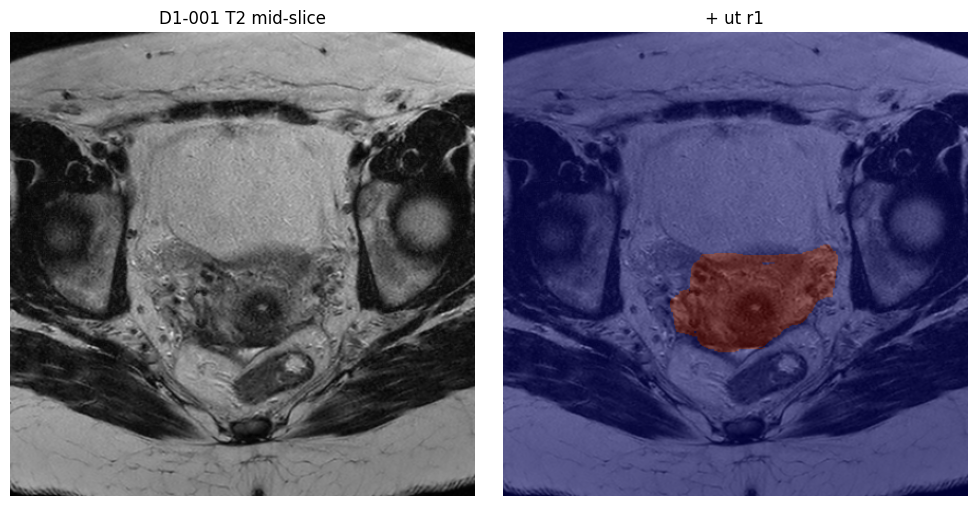

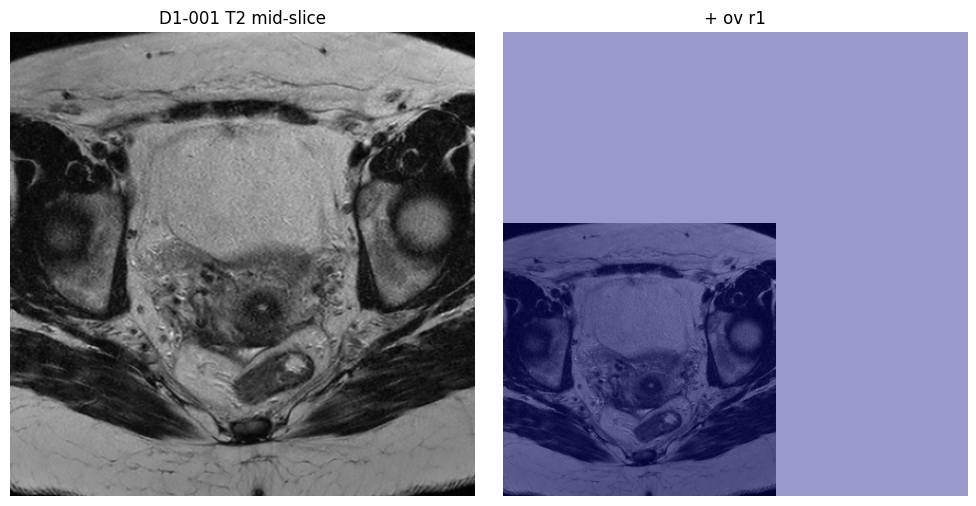

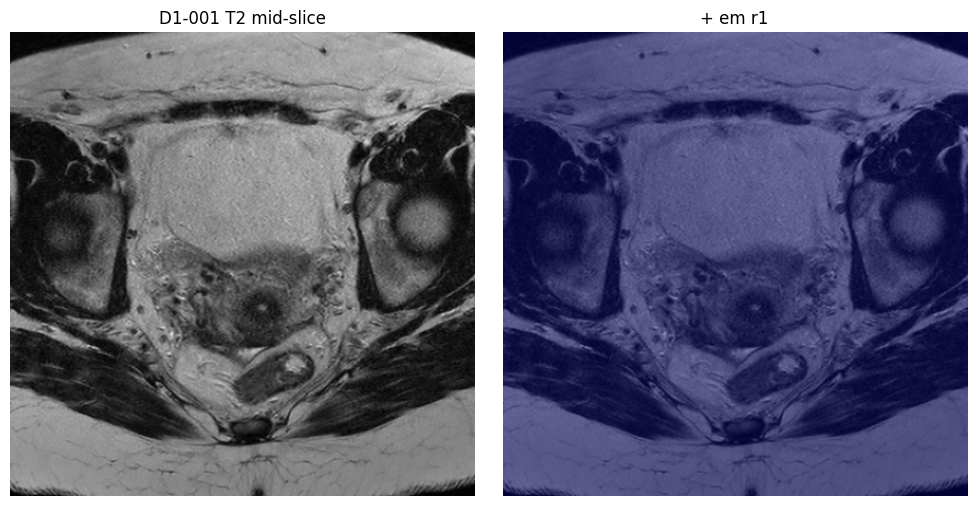

In [13]:
# visual sanity check
def show_overlay(subject, centre, modality_img="T2", modality_mask="ut", rater="1"):
    sdir = ROOT / centre / subject
    img_path = sdir / f"{subject}_{modality_img}.nii.gz"
    mask_path = sdir / f"{subject}_{modality_mask}_r{rater}.nii.gz"
    if not img_path.exists():
        print("Missing:", img_path); return
    if not mask_path.exists():
        print("Missing:", mask_path); return

    img = nib.load(str(img_path)).get_fdata()
    mask = nib.load(str(mask_path)).get_fdata()
    mid = img.shape[2] // 2

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(img[:, :, mid].T, cmap="gray", origin="lower")
    axes[0].set_title(f"{subject} {modality_img} mid-slice")
    axes[1].imshow(img[:, :, mid].T, cmap="gray", origin="lower")
    axes[1].imshow(mask[:, :, mid].T, alpha=0.4, cmap="jet", origin="lower")
    axes[1].set_title(f"+ {modality_mask} r{rater}")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

# Try a few subjects
show_overlay("D1-001", "D1_MHS", "T2", "ut", "1")
show_overlay("D1-001", "D1_MHS", "T2", "ov", "1")
show_overlay("D1-001", "D1_MHS", "T2", "em", "1")